# icon_0.33deg: the latest raw snapshot

Reads the newest `raw_ocean_icon033_seg*/pe=*/n=*/` snapshot directly from the
`.npy` blocks -- no `raw2nc.py`, nothing reassembled on disk first.

Two corrections to the first version of this notebook:

* **the wet mask was inverted.** `kbot` is the pyOM2 index of the deepest wet
  level with level 1 at the SEA FLOOR, and `make_topo_masks` sets
  `maskT[k] = 1 where kbot <= k`, so the wet levels are the **top**
  `nz - kbot + 1` of the column. The first version had it the other way round
  and turned a 13-level shelf column into a 6069 m one.
* **the scans read every block once**, not once per level. The locator used to
  open 936 files for each of 128 levels; now it opens 936 in total, which is
  why it took so long.

In [1]:
import os, glob, re
import numpy as np
import matplotlib.pyplot as plt
from netCDF4 import Dataset

RUNDIR   = '/work/uo0780/u241155/pyOM3_real/icon033_spinup'
GRIDFILE = os.path.join(RUNDIR, 'grid_topo.nc')
SNAPGLOB = 'raw_ocean_icon033_seg*'      # one directory per job segment
STEP     = None                         # None = the newest step available

plt.rcParams['figure.figsize'] = (11, 4.5)
plt.rcParams['image.cmap'] = 'RdYlBu_r'

## Snapshot, grid and topography

`pe_realistic` writes `zt` as **height above the bottom**, so a level's depth
below the surface is `zt.sum() - zt[k]`; index 0 is the sea floor and -1 the
surface.

In [2]:
# newest segment FIRST, but a segment that ended before its next snapshot
# interval holds only the pe= directories, so fall back until one has data
segdirs = sorted(glob.glob(os.path.join(RUNDIR, SNAPGLOB)))
if not segdirs:
    raise SystemExit('no snapshot directory matching %s in %s' % (SNAPGLOB, RUNDIR))
SNAPDIR, steps = None, []
for d in reversed(segdirs):
    s = sorted({int(re.search(r'n=(\d+)$', p).group(1))
                for p in glob.glob(os.path.join(d, 'pe=*', 'n=*'))})
    if s:
        SNAPDIR, steps = d, s
        break
if SNAPDIR is None:
    raise SystemExit('none of %d segment directories holds a snapshot yet' % len(segdirs))
step = steps[-1] if STEP is None else STEP

xt = np.load(os.path.join(SNAPDIR, 'xt.npy'))
yt = np.load(os.path.join(SNAPDIR, 'yt.npy'))
zt = np.load(os.path.join(SNAPDIR, 'zt.npy'))          # height above the bottom
npx, npy = np.load(os.path.join(SNAPDIR, 'decomposition.npy'))
nx, ny, nz = len(xt), len(yt), len(zt)

with Dataset(GRIDFILE) as f:
    kbot = np.asarray(f.variables['kbot'][:], int)
    dzt  = np.asarray(f.variables['dzt'][:], float)     # bottom first

depth_of = dzt.sum() - zt                               # metres below the surface
# WET: maskT[k] = 1 where kbot <= k (1-based, level 1 at the sea floor), so
# with the 0-based bottom-first index used here a cell is wet for k >= kbot-1
wet = (np.arange(nz)[:, None, None] >= (kbot - 1)[None]) & (kbot > 0)[None]
below = np.cumsum(dzt[::-1])[::-1]                      # below[k] = sum(dzt[k:])
col_depth = np.where(kbot > 0, below[np.clip(kbot - 1, 0, nz - 1)], 0.0)
nwet_col = np.where(kbot > 0, nz - kbot + 1, 0)         # wet levels in a column

t_days = float(np.load(glob.glob(os.path.join(SNAPDIR, 'pe=*', 'n=%d' % step, 't.npy'))[0]))/86400.
print('%s   step %d   t = %.3f d   (%d steps available: %s ...)'
      % (os.path.basename(SNAPDIR), step, t_days, len(steps), steps[:4]))
print('grid %d x %d x %d on %d x %d ranks | %d wet cells | deepest column %.0f m '
      '(%d levels) | top cell %.2f m'
      % (nx, ny, nz, npx, npy, wet.sum(), col_depth.max(), nwet_col.max(), dzt[-1]))

raw_ocean_icon033_seg0144000   step 156000   t = 390.000 d   (2 steps available: [144000, 156000] ...)
grid 1080 x 689 x 128 on 72 x 13 ranks | 48994481 wet cells | deepest column 6100 m (128 levels) | top cell 2.05 m


## The block loader

Every rank wrote its own interior block. The global field is assembled with
the decomposition the model used: `x_blk = ceil(nx/npx)`, last row and column
truncated, `pe = (blk_y-1)*npx + (blk_x-1)`.

`load` is for single levels and 2-D fields. Anything that needs the whole
column uses `scan`, which walks the blocks once.

In [3]:
x_blk, y_blk = (nx-1)//npx + 1, (ny-1)//npy + 1
BLOCKS = []
for by in range(npy):
    for bx in range(npx):
        BLOCKS.append((by*npx + bx, by*y_blk, min((by+1)*y_blk, ny),
                       bx*x_blk, min((bx+1)*x_blk, nx)))

def _npy(pe, var):
    return os.path.join(SNAPDIR, 'pe=%d' % pe, 'n=%d' % step, '%s.npy' % var)

def load(var, k=None):
    """Global field: one level (k, 0 = sea floor, -1 = surface), a 2-D field,
    or the whole 3-D field with k=None -- 762 MB in float64, ask deliberately."""
    out = None
    for pe, j0, j1, i0, i1 in BLOCKS:
        a = np.load(_npy(pe, var), mmap_mode='r')
        if a.ndim == 2:
            if out is None: out = np.empty((ny, nx))
            out[j0:j1, i0:i1] = a
        elif k is None:
            if out is None: out = np.empty((nz, ny, nx))
            out[:, j0:j1, i0:i1] = a
        else:
            if out is None: out = np.empty((ny, nx))
            out[j0:j1, i0:i1] = a[k]
    return out

def scan(fn):
    """Apply fn(block_dict, j0, j1, i0, i1) to every rank's block in turn.
    One pass over the files, nothing global held."""
    for pe, j0, j1, i0, i1 in BLOCKS:
        yield fn, pe, j0, j1, i0, i1

def block_of(j, i):
    """(pe, j-in-block, i-in-block) of a global point."""
    for pe, j0, j1, i0, i1 in BLOCKS:
        if j0 <= j < j1 and i0 <= i < i1:
            return pe, j - j0, i - i0
    raise IndexError((j, i))

def mask(a, k=None):
    m = wet if a.ndim == 3 else (wet[k] if k is not None else kbot > 0)
    return np.where(m, a, np.nan)

print('variables written:', sorted(os.path.basename(p)[:-4] for p in
      glob.glob(os.path.join(SNAPDIR, 'pe=0', 'n=%d' % step, '*.npy'))))

variables written: ['K_diss_E', 'K_diss_L', 'p_h', 'p_s', 'salt', 't', 'temp', 'tke', 'u', 'v', 'w']


## Surface maps

SST -1.81 .. 31.40 C | SSS 24.52 .. 39.29 | speed max 2.81 m/s | SSH -2.00 .. 2.01 m


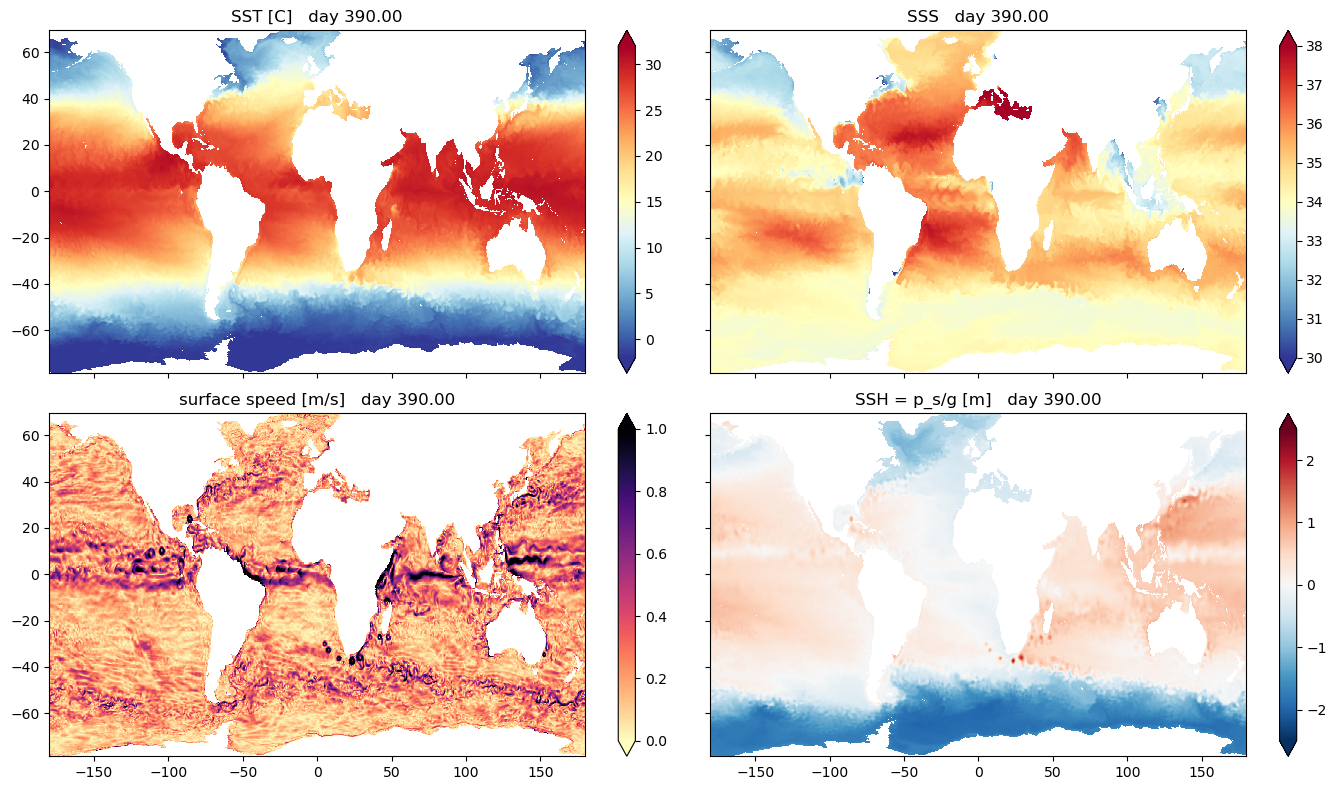

In [4]:
ks = -1
sst = mask(load('temp', ks), ks); sss = mask(load('salt', ks), ks)
us  = mask(load('u', ks), ks);    vs  = mask(load('v', ks), ks)
ssh = mask(load('p_s')/9.81);     spd = np.hypot(us, vs)

fig, ax = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
for a, fld, ttl, kw in ((ax[0,0], sst, 'SST [C]', dict(vmin=-2, vmax=32)),
                        (ax[0,1], sss, 'SSS', dict(vmin=30, vmax=38)),
                        (ax[1,0], spd, 'surface speed [m/s]', dict(vmin=0, vmax=1.0, cmap='magma_r')),
                        (ax[1,1], ssh, 'SSH = p_s/g [m]', dict(vmin=-2.5, vmax=2.5, cmap='RdBu_r'))):
    h = a.pcolormesh(xt, yt, fld, shading='auto', **kw)
    plt.colorbar(h, ax=a, extend='both'); a.set_title('%s   day %.2f' % (ttl, t_days))
fig.tight_layout()
print('SST %.2f .. %.2f C | SSS %.2f .. %.2f | speed max %.2f m/s | SSH %.2f .. %.2f m'
      % (np.nanmin(sst), np.nanmax(sst), np.nanmin(sss), np.nanmax(sss),
         np.nanmax(spd), np.nanmin(ssh), np.nanmax(ssh)))

## Surface extremes: how many cells, how deep are they, how isolated

The surface tracer forcing is a flux divided by the top cell thickness, so on
a 2.05 m cell an hour of heavy ERA5 precipitation or a strong net heat flux
moves the top cell far more than it would on the 10 m cells these settings
were tuned with. The question is therefore not whether extremes exist but
whether they sit in a handful of shallow, laterally enclosed cells -- which is
a forcing-over-dz problem -- or spread over open ocean, which would be
something else.

`n_open` counts how many of the four horizontal neighbours are wet at the
surface: 0 to 2 means the cell can barely exchange sideways.

SSS outside 32 .. 38 : 4839 cells (1.0495 % of the wet surface)
   of those: 2187 in columns of <= 20 levels, 412 with <= 2 open neighbours, median column depth 79 m
SST outside -2 .. 32 : 0 cells (0.0000 % of the wet surface)


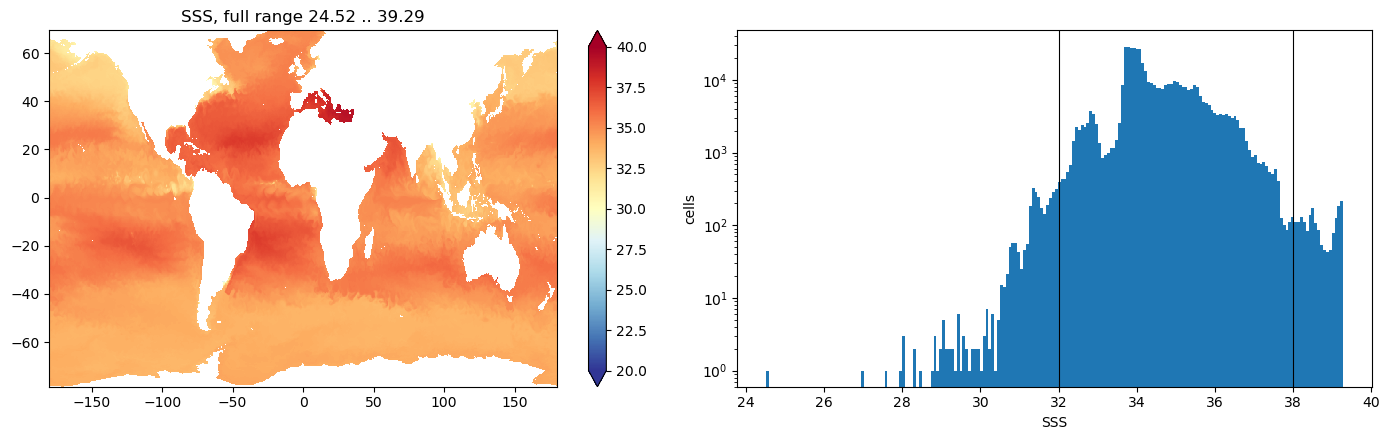

In [5]:
wetS = wet[ks]
nb_open = np.zeros((ny, nx), int)
for sh, ax_ in ((1, 1), (-1, 1), (1, 0), (-1, 0)):
    nb_open += np.roll(wetS, sh, axis=ax_).astype(int)

for nm, fld, lo, hi in (('SSS', sss, 32.0, 38.0), ('SST', sst, -2.0, 32.0)):
    bad = np.where(wetS, (fld < lo) | (fld > hi), False)
    n = int(bad.sum())
    print('%s outside %.0f .. %.0f : %d cells (%.4f %% of the wet surface)'
          % (nm, lo, hi, n, 100.0*n/wetS.sum()))
    if n:
        print('   of those: %d in columns of <= 20 levels, %d with <= 2 open '
              'neighbours, median column depth %.0f m'
              % (int((nwet_col[bad] <= 20).sum()), int((nb_open[bad] <= 2).sum()),
                 float(np.median(col_depth[bad]))))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
h = ax[0].pcolormesh(xt, yt, np.where(wetS, sss, np.nan), shading='auto',
                     vmin=20, vmax=40); plt.colorbar(h, ax=ax[0], extend='both')
ax[0].set_title('SSS, full range %.2f .. %.2f' % (np.nanmin(sss), np.nanmax(sss)))
ax[1].hist(sss[wetS], bins=200, log=True); ax[1].set_xlabel('SSS'); ax[1].set_ylabel('cells')
ax[1].axvline(32, c='k', lw=0.8); ax[1].axvline(38, c='k', lw=0.8)
fig.tight_layout()

## Locator: the fastest water, and how many cells are fast

One pass over the blocks, so this is seconds rather than minutes.

max |u_h| = 2.809 m/s  at  lon 42.00  lat -2.00   level k=127, depth 1 m
column there: 100 wet levels, 2366 m deep, 4 of 4 surface neighbours wet
  u     here     1.959 | W    1.889 E    1.426 S    0.359 N    1.400
  v     here     2.013 | W    0.000 E    2.013 S    1.700 N    1.072
  w     here    -0.000 | W   -0.000 E    0.000 S    0.000 N   -0.000
  temp  here    26.650 | W   26.608 E   26.662 S   26.737 N   26.448
  salt  here    34.827 | W   34.802 E   34.876 S   34.897 N   34.820
  column depth [m]: here 2366 | W 1556 E 2809 S 2715 N 1612
cells with |u| > 0.5 m/s :   696825  (1.4223 % of the wet cells)
cells with |u| > 1.0 m/s :    69785  (0.1424 % of the wet cells)
cells with |u| > 2.0 m/s :     2285  (0.0047 % of the wet cells)
cells with |u| > 3.0 m/s :        0  (0.0000 % of the wet cells)


Text(0.5, 1.0, 'column maximum of |u|, day 390.00')

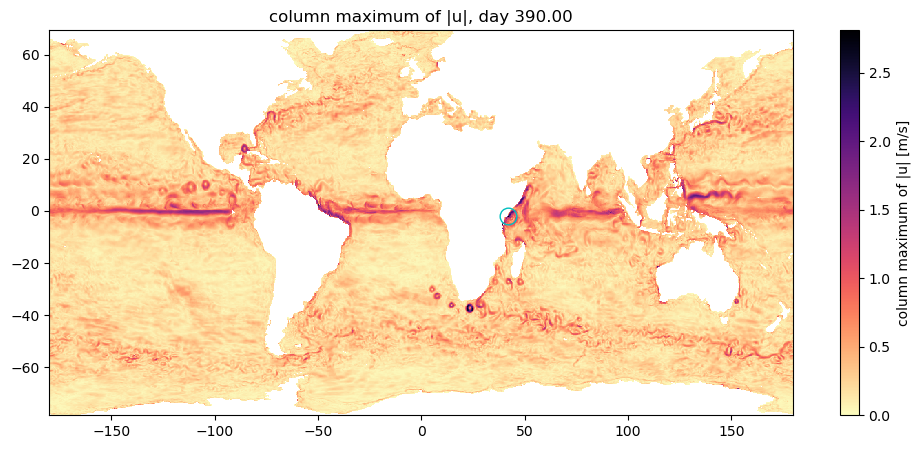

In [6]:
thr = np.array([0.5, 1.0, 2.0, 3.0])
cnt = np.zeros(len(thr), int)
fast = np.zeros((ny, nx))
best = (-1.0, None)
for pe, j0, j1, i0, i1 in BLOCKS:
    u = np.asarray(np.load(_npy(pe, 'u'), mmap_mode='r'))
    v = np.asarray(np.load(_npy(pe, 'v'), mmap_mode='r'))
    a = np.where(wet[:, j0:j1, i0:i1], np.hypot(u, v), 0.0)
    cnt += (a[None] > thr[:, None, None, None]).sum(axis=(1, 2, 3))
    fast[j0:j1, i0:i1] = a.max(axis=0)
    m = float(a.max())
    if m > best[0]:
        kk = np.unravel_index(int(np.argmax(a)), a.shape)
        best = (m, (kk[0], j0 + kk[1], i0 + kk[2]))
umax, (k, j, i) = best
print('max |u_h| = %.3f m/s  at  lon %.2f  lat %.2f   level k=%d, depth %.0f m'
      % (umax, xt[i], yt[j], k, depth_of[k]))
print('column there: %d wet levels, %.0f m deep, %d of 4 surface neighbours wet'
      % (nwet_col[j, i], col_depth[j, i], nb_open[j, i]))
for nm in ('u', 'v', 'w', 'temp', 'salt'):
    v_ = load(nm, k)
    print('  %-5s here %9.3f | W %8.3f E %8.3f S %8.3f N %8.3f'
          % (nm, v_[j, i], v_[j, i-1], v_[j, (i+1) % nx], v_[j-1, i], v_[min(j+1, ny-1), i]))
print('  column depth [m]: here %.0f | W %.0f E %.0f S %.0f N %.0f'
      % (col_depth[j, i], col_depth[j, i-1], col_depth[j, (i+1) % nx],
         col_depth[j-1, i], col_depth[min(j+1, ny-1), i]))
for t_, c in zip(thr, cnt):
    print('cells with |u| > %.1f m/s : %8d  (%.4f %% of the wet cells)'
          % (t_, c, 100.0*c/wet.sum()))

plt.figure(figsize=(12, 5))
h = plt.pcolormesh(xt, yt, np.where(kbot > 0, fast, np.nan), shading='auto',
                   vmin=0, vmax=max(1.0, umax), cmap='magma_r')
plt.colorbar(h, label='column maximum of |u| [m/s]'); plt.plot(xt[i], yt[j], 'co', mfc='none', ms=12)
plt.title('column maximum of |u|, day %.2f' % t_days)

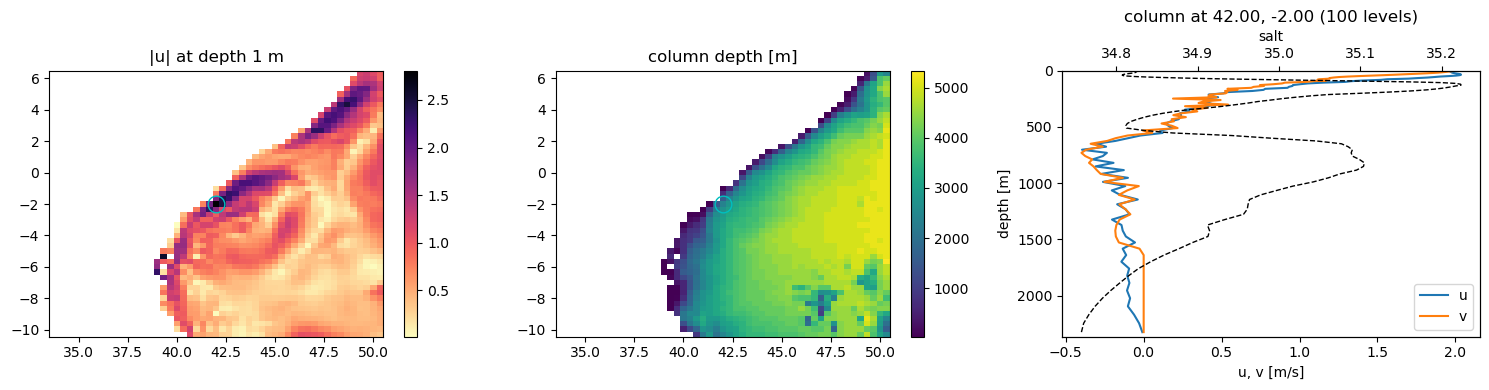

In [7]:
# window around the hot point, and its column (one block read per variable)
w = 25
js, je = max(j-w, 0), min(j+w+1, ny)
isl = np.arange(i-w, i+w+1) % nx
xw = xt[isl].astype(float); xw = np.where(xw < xw[0], xw + 360.0, xw)
uk = mask(load('u', k), k); vk = mask(load('v', k), k)
spk = np.hypot(uk, vk)

pe, jb, ib = block_of(j, i)
prof = {nm: np.asarray(np.load(_npy(pe, nm), mmap_mode='r'))[:, jb, ib]
        for nm in ('u', 'v', 'temp', 'salt')}
kw_ = nwet_col[j, i]

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
h = ax[0].pcolormesh(xw, yt[js:je], spk[js:je][:, isl], shading='auto', cmap='magma_r')
ax[0].plot(xw[w], yt[j], 'co', mfc='none', ms=12); plt.colorbar(h, ax=ax[0])
ax[0].set_title('|u| at depth %.0f m' % depth_of[k])
h = ax[1].pcolormesh(xw, yt[js:je], np.where(kbot > 0, col_depth, np.nan)[js:je][:, isl],
                     shading='auto', cmap='viridis')
ax[1].plot(xw[w], yt[j], 'co', mfc='none', ms=12); plt.colorbar(h, ax=ax[1])
ax[1].set_title('column depth [m]')
d = depth_of[nz-kw_:]
ax[2].plot(prof['u'][nz-kw_:], d, label='u'); ax[2].plot(prof['v'][nz-kw_:], d, label='v')
a2 = ax[2].twiny(); a2.plot(prof['salt'][nz-kw_:], d, 'k--', lw=1)
ax[2].set_ylim(col_depth[j, i], 0); ax[2].set_xlabel('u, v [m/s]'); a2.set_xlabel('salt')
ax[2].set_ylabel('depth [m]'); ax[2].legend(loc='lower right')
ax[2].set_title('column at %.2f, %.2f (%d levels)' % (xt[i], yt[j], kw_))
fig.tight_layout()

## Zonal mean temperature and a meridional section

/tmp/ipykernel_1737964/3252496407.py:4: RuntimeWarning: Mean of empty slice
  zm = np.nanmean(T3, axis=2)


temperature -1.91 .. 33.35 C | 8237850 interfaces warmer below than above, worst 3.73 K


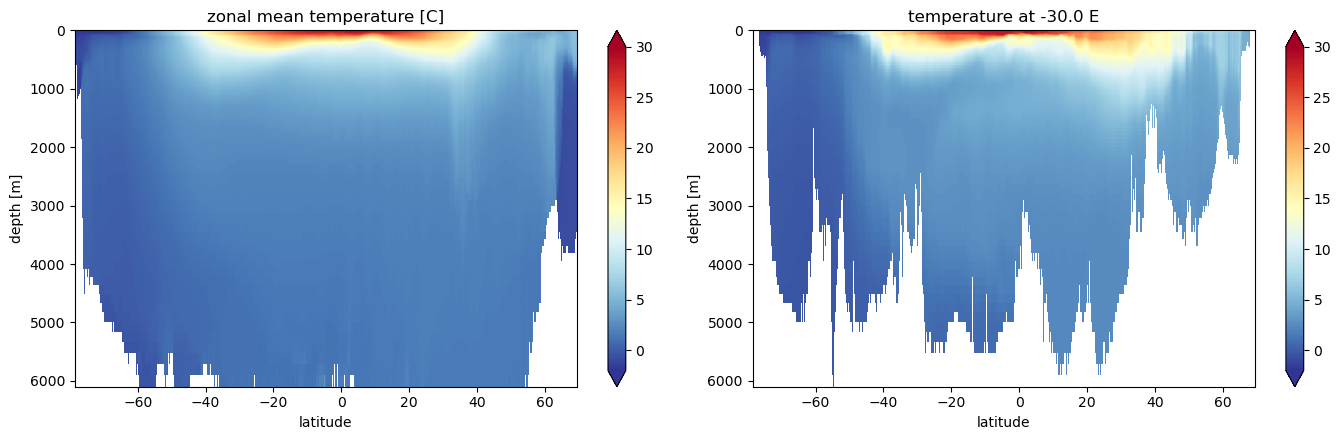

In [8]:
LON_SECTION = -30.0
isec = int(np.argmin(np.abs(xt - LON_SECTION)))
T3 = mask(load('temp'))                  # the one full 3-D read
zm = np.nanmean(T3, axis=2)
sec = T3[:, :, isec]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, fld, ttl in ((ax[0], zm, 'zonal mean temperature [C]'),
                    (ax[1], sec, 'temperature at %.1f E' % xt[isec])):
    h = a.pcolormesh(yt, depth_of, fld, shading='auto', vmin=-2, vmax=30)
    plt.colorbar(h, ax=a, extend='both'); a.set_title(ttl)
    a.set_ylim(col_depth.max(), 0); a.set_xlabel('latitude'); a.set_ylabel('depth [m]')
fig.tight_layout()

# level k+1 lies ABOVE level k, so a stable column has T rising with the index
dT = np.diff(np.where(wet, T3, np.nan), axis=0)
print('temperature %.2f .. %.2f C | %d interfaces warmer below than above, worst %.2f K'
      % (np.nanmin(T3), np.nanmax(T3), int(np.nansum(dT < -1e-3)),
         -float(np.nanmin(dT)) if np.isfinite(np.nanmin(dT)) else 0.0))
del T3

## Mixed layer depth, and the observed climatology

The depth where sigma_0 exceeds its value at 10 m by 0.03 kg/m3 (de Boyer
Montegut et al. 2004), from the model's own equation of state where pyOM3 is
importable, else gsw, else a linear proxy. One pass over the blocks: the
column density is never held globally.

A column that is unstratified to the bottom gets its own depth, and a column
shallower than the 10 m reference gets it too; both are the honest answer
rather than a missing value.

WHAT THIS CAN AND CANNOT SAY. A snapshot is ONE INSTANT, the climatology is a
monthly mean of many years. The comparison below is therefore against the
month the snapshot falls in, and the annual MAXIMUM of the climatology is
drawn beside it only as the bound the deep-convection season has to reach.
For the real comparison use the monthly means (`ocean_mean_*`), which is what
the alpha_CB and TKE ensembles were scored with.

Set `OBSFILE` to the de Boyer Montegut climatology on this machine (v2023,
SEANOE 10.17882/91774). Without it the model MLD is still mapped.

In [ ]:
# --- MLD from the snapshot, and the observed climatology -------------------
# de Boyer Montegut: the depth where sigma_0 exceeds its value at 10 m by
# DSIG. One pass over the blocks, the density from the model's own equation
# of state where pyOM3 is importable.
OBSFILE = os.path.join(RUNDIR, 'mld_DR003_c1m_reg2.0.nc')   # <- your obs file
OBSFILE_ALT = ['/work/uo0780/u241155/obs/mld_deboyer_2023.nc',
               os.path.join(RUNDIR, '..', 'obs', 'mld_deboyer_2023.nc')]
DSIG, ZREF = 0.03, 10.0
FORCING_START, CYCLE_DAYS = '1990-05-01', 365.0    # as the run script sets them
MONTH = None                       # None = the month of the snapshot's forcing date

import datetime, warnings
try:
    import sys as _s
    _s.path.insert(0, os.path.join(RUNDIR, '..'))
    from pyOM3.density import get_rho
    sigma0 = lambda S, T: np.asarray(get_rho(S, T, 0.0*S, 5))
    eos = 'pyOM3 TEOS-10 (eq_of_state 5)'
except Exception:
    try:
        import gsw
        sigma0 = lambda S, T: gsw.sigma0(S, T)
        eos = 'gsw.sigma0'
    except Exception:
        sigma0 = lambda S, T: 1024.0*(-1.7e-4*(T - 10.0) + 7.6e-4*(S - 35.0))
        eos = 'linear proxy (no pyOM3, no gsw)'

# ---- model MLD, block by block (top-first depth axis)
d_top = depth_of[::-1]                                   # 0 = surface, increasing
kref = int(np.argmin(np.abs(d_top - ZREF)))              # the level nearest 10 m
mld = np.full((ny, nx), np.nan)
for pe, j0, j1, i0, i1 in BLOCKS:
    T = np.asarray(np.load(_npy(pe, 'temp'), mmap_mode='r'))[::-1]
    S = np.asarray(np.load(_npy(pe, 'salt'), mmap_mode='r'))[::-1]
    w = wet[::-1, j0:j1, i0:i1]
    sig = np.where(w, sigma0(S, T), np.nan)
    tgt = sig[kref] + DSIG                               # (ny_b, nx_b)
    over = np.where(np.isfinite(sig[kref + 1:]), sig[kref + 1:] > tgt[None], False)
    has = over.any(axis=0)
    k1 = np.where(has, over.argmax(axis=0) + kref + 1, 0)  # first level past it
    kk, jj, ii = k1, *np.indices(k1.shape)
    s1, s0 = sig[kk, jj, ii], sig[kk - 1, jj, ii]
    z1, z0 = d_top[kk], d_top[kk - 1]
    f = np.where(s1 > s0, (tgt - s0)/np.where(s1 > s0, s1 - s0, 1.0), 0.0)
    m = np.where(has, z0 + f*(z1 - z0), col_depth[j0:j1, i0:i1])  # unstratified: the floor
    mld[j0:j1, i0:i1] = np.where(kbot[j0:j1, i0:i1] > 0, m, np.nan)

d0 = datetime.datetime.strptime(FORCING_START, '%Y-%m-%d') + datetime.timedelta(
        days=float(np.mod(t_days, CYCLE_DAYS) if CYCLE_DAYS else t_days))
month = d0.month if MONTH is None else MONTH
print('MLD from %s, sigma_0 + %.2f kg/m3 above its value at %.0f m (level %d, %.1f m)'
      % (eos, DSIG, ZREF, kref, d_top[kref]))
print('model day %.2f = %s, so the observed month is %d' % (t_days, d0.strftime('%d %b'), month))
print('model MLD: median %.0f m, 95th %.0f m, max %.0f m'
      % (np.nanmedian(mld), np.nanpercentile(mld, 95), np.nanmax(mld)))

# ---- observed climatology: that month and the annual maximum
obs = None
for p in [OBSFILE] + OBSFILE_ALT:
    if os.path.exists(p):
        with Dataset(p) as f:
            v = [n for n in ('mld', 'mlotst', 'mld_dr003', 'MLD', 'mld_da_mean')
                 if n in f.variables]
            if not v:
                v = [n for n, var in f.variables.items() if var.ndim == 3]
            a = np.asarray(f.variables[v[0]][:], float)
            a = np.where(np.isfinite(a) & (a > 0) & (a < 1e4), a, np.nan)
            ln = [n for n in ('lon', 'longitude', 'x') if n in f.variables][0]
            lt = [n for n in ('lat', 'latitude', 'y') if n in f.variables][0]
            obs = (a, np.asarray(f.variables[ln][:], float),
                   np.asarray(f.variables[lt][:], float), os.path.basename(p), v[0])
        break
if obs is None:
    print('no MLD climatology found; set OBSFILE. Plotting the model alone.')

fig, ax = plt.subplots(2 if obs is not None else 1, 2,
                       figsize=(14, 8 if obs is not None else 4.5), squeeze=False)
h = ax[0, 0].pcolormesh(xt, yt, np.log10(mld), shading='auto', vmin=1, vmax=3.2, cmap='viridis')
plt.colorbar(h, ax=ax[0, 0], extend='both', label='log10 m')
ax[0, 0].set_title('model MLD, day %.2f' % t_days)
ax[0, 1].hist(mld[np.isfinite(mld)], bins=np.logspace(0, 3.5, 120), log=True)
ax[0, 1].set_xscale('log'); ax[0, 1].set_xlabel('MLD [m]'); ax[0, 1].set_title('distribution')

if obs is not None:
    A, olon, olat, oname, ovar = obs
    omon = A[month - 1] if A.shape[0] == 12 else A[0]
    omax = np.nanmax(A, axis=0) if A.shape[0] == 12 else A[0]
    # model onto the obs grid: mean of the model cells inside each obs cell
    ow = np.mod(olon, 360.0); mw = np.mod(xt, 360.0)
    ix = np.clip(np.searchsorted(np.sort(ow), mw) - 1, 0, len(ow) - 1)
    iy = np.clip(np.searchsorted(olat, yt) - 1, 0, len(olat) - 1)
    num = np.zeros_like(omon); den = np.zeros_like(omon)
    good = np.isfinite(mld)
    np.add.at(num, (iy[:, None].repeat(nx, 1)[good], ix[None, :].repeat(ny, 0)[good]), mld[good])
    np.add.at(den, (iy[:, None].repeat(nx, 1)[good], ix[None, :].repeat(ny, 0)[good]), 1.0)
    mobs = np.where(den > 0, num/np.maximum(den, 1), np.nan)
    both = np.isfinite(mobs) & np.isfinite(omon)
    r = np.log2(mobs[both]/omon[both])
    print('%s (%s): month %d, %d obs cells compared' % (oname, ovar, month, both.sum()))
    print('  model %6.1f m  obs %6.1f m  bias %+6.1f m  rms log2 ratio %.3f'
          % (np.nanmean(mobs[both]), np.nanmean(omon[both]),
             np.nanmean(mobs[both] - omon[both]), np.sqrt(np.mean(r**2))))
    bm = np.isfinite(mobs) & np.isfinite(omax)
    print('  against the ANNUAL MAXIMUM of the climatology: bias %+6.1f m '
          '(a snapshot is one month, so this is only a bound)'
          % np.nanmean(mobs[bm] - omax[bm]))
    h = ax[1, 0].pcolormesh(olon, olat, np.log10(omon), shading='auto',
                            vmin=1, vmax=3.2, cmap='viridis')
    plt.colorbar(h, ax=ax[1, 0], extend='both', label='log10 m')
    ax[1, 0].set_title('observed MLD, month %d' % month)
    h = ax[1, 1].pcolormesh(olon, olat, np.log2(mobs/omon), shading='auto',
                            vmin=-2, vmax=2, cmap='RdBu_r')
    plt.colorbar(h, ax=ax[1, 1], extend='both', label='log2 model/obs')
    ax[1, 1].set_title('model / obs, month %d' % month)
fig.tight_layout()

if obs is not None:
    fig, a = plt.subplots(figsize=(11, 4))
    with warnings.catch_warnings():          # latitudes with no model water
        warnings.simplefilter('ignore', RuntimeWarning)
        a.plot(olat, np.nanmean(mobs, axis=1), label='model, day %.0f' % t_days)
        a.plot(olat, np.nanmean(omon, axis=1), label='obs, month %d' % month)
        a.plot(olat, np.nanmean(omax, axis=1), 'k--', lw=1, label='obs, annual maximum')
    a.set_yscale('log'); a.set_xlabel('latitude'); a.set_ylabel('zonal mean MLD [m]')
    a.legend(); a.grid(alpha=.3); a.invert_yaxis()